<a href="https://colab.research.google.com/github/tanvi118/AISR_LAB_500120658/blob/main/Robotics_Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-7

Comparing SGD, Adam and LBFGS.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import random

np.random.seed(42)
random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Experiment 7A
# Reactive Braitenberg controller for e-puck style robot

MAX_SPEED = 6.28

# Mirror-image Braitenberg weights
W_LEFT = np.array([
    -1.3, -1.0, -0.7, -0.2,
     0.2,  0.7,  1.0,  1.3
])

W_RIGHT = np.array([
     1.3,  1.0,  0.7,  0.2,
    -0.2, -0.7, -1.0, -1.3
])


def braitenberg_controller(sensor_values,
                           cruise=0.5,
                           gain=0.7,
                           speed=1.0):

    # Normalize Webots-like IR values to 0-1
    x = np.minimum(sensor_values, 4096.0) / 4096.0

    vl = cruise + gain * np.sum(W_LEFT * x)
    vr = cruise + gain * np.sum(W_RIGHT * x)

    vl = np.clip(vl, -1, 1)
    vr = np.clip(vr, -1, 1)

    left_speed = vl * MAX_SPEED * speed
    right_speed = vr * MAX_SPEED * speed

    return left_speed, right_speed

In [3]:
# Simulated IR sensor readings

tests = {
    "No obstacle":
        np.zeros(8),

    "Obstacle on right":
        np.array([4000, 3000, 1500, 500, 0, 0, 0, 0]),

    "Obstacle on left":
        np.array([0, 0, 0, 0, 500, 1500, 3000, 4000]),

    "Obstacle ahead":
        np.array([3500, 3000, 1000, 0, 0, 1000, 3000, 3500])
}


for name, sensors in tests.items():

    left, right = braitenberg_controller(sensors)

    print("\n", name)
    print("Left wheel :", round(left, 3), "rad/s")
    print("Right wheel:", round(right, 3), "rad/s")


 No obstacle
Left wheel : 3.14 rad/s
Right wheel: 3.14 rad/s

 Obstacle on right
Left wheel : -6.28 rad/s
Right wheel: 6.28 rad/s

 Obstacle on left
Left wheel : 6.28 rad/s
Right wheel: -6.28 rad/s

 Obstacle ahead
Left wheel : 3.14 rad/s
Right wheel: 3.14 rad/s


In [4]:
N_ROBOTS = 5
ARENA = 1.6
DT = 0.05
SIM_TIME = 120

steps = int(SIM_TIME / DT)

positions = np.random.uniform(
    -ARENA/2 + 0.1,
    ARENA/2 - 0.1,
    size=(N_ROBOTS, 2)
)

angles = np.random.uniform(
    -np.pi,
    np.pi,
    size=N_ROBOTS
)

trajectories = [
    [positions[i].copy()]
    for i in range(N_ROBOTS)
]


def simulated_sensors(position, angle):

    sensors = np.zeros(8)

    # Detect proximity to arena walls
    wall_distance = min(
        ARENA/2 - abs(position[0]),
        ARENA/2 - abs(position[1])
    )

    if wall_distance < 0.15:

        strength = (
            (0.15 - wall_distance)
            / 0.15
            * 4096
        )

        # approximate front obstacle
        sensors[0] = strength
        sensors[1] = strength
        sensors[6] = strength
        sensors[7] = strength

    return sensors

In [5]:
WHEEL_RADIUS = 0.0205
AXLE = 0.052

for step in range(steps):

    for i in range(N_ROBOTS):

        sensors = simulated_sensors(
            positions[i],
            angles[i]
        )

        vl, vr = braitenberg_controller(
            sensors,
            cruise=0.5
        )

        linear_velocity = (
            WHEEL_RADIUS * (vr + vl) / 2
        )

        angular_velocity = (
            WHEEL_RADIUS * (vr - vl) / AXLE
        )

        angles[i] += angular_velocity * DT

        positions[i, 0] += (
            linear_velocity *
            np.cos(angles[i]) *
            DT
        )

        positions[i, 1] += (
            linear_velocity *
            np.sin(angles[i]) *
            DT
        )

        # Keep robot inside arena
        positions[i] = np.clip(
            positions[i],
            -ARENA/2 + 0.02,
            ARENA/2 - 0.02
        )

        trajectories[i].append(
            positions[i].copy()
        )

print("Swarm simulation completed.")

Swarm simulation completed.


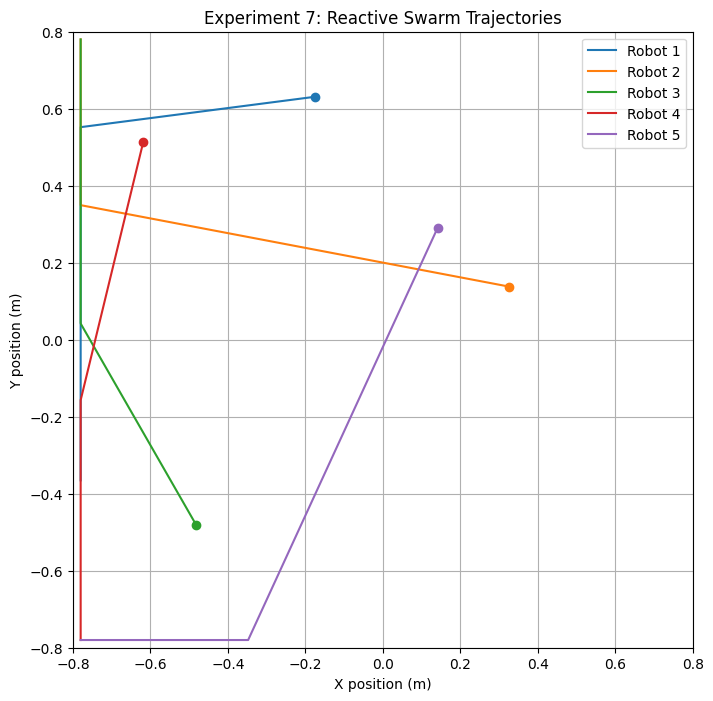

In [6]:
plt.figure(figsize=(8, 8))

for i, trajectory in enumerate(trajectories):

    trajectory = np.array(trajectory)

    plt.plot(
        trajectory[:, 0],
        trajectory[:, 1],
        label=f"Robot {i+1}"
    )

    plt.scatter(
        trajectory[0, 0],
        trajectory[0, 1],
        marker="o"
    )

plt.xlim(-ARENA/2, ARENA/2)
plt.ylim(-ARENA/2, ARENA/2)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")

plt.title(
    "Experiment 7: Reactive Swarm Trajectories"
)

plt.legend()
plt.grid()

plt.show()

Arena coverage = 14.11%


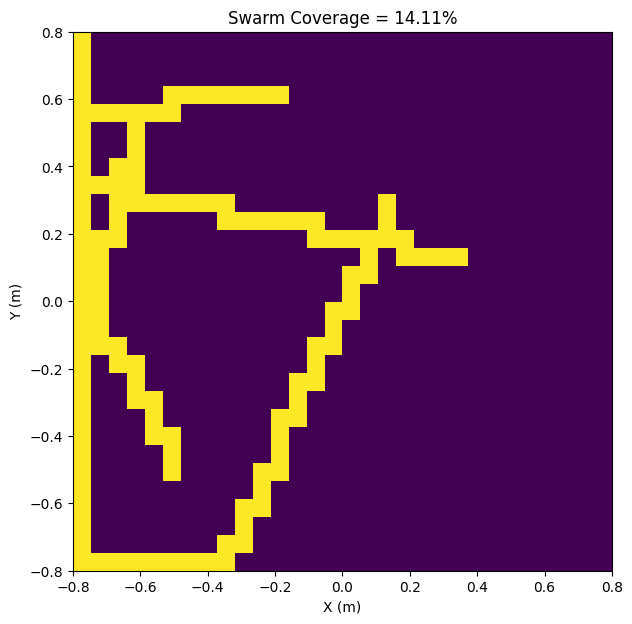

In [7]:
GRID_SIZE = 30

visited = np.zeros(
    (GRID_SIZE, GRID_SIZE),
    dtype=bool
)

for trajectory in trajectories:

    trajectory = np.array(trajectory)

    for x, y in trajectory:

        gx = int(
            (x + ARENA/2)
            / ARENA
            * GRID_SIZE
        )

        gy = int(
            (y + ARENA/2)
            / ARENA
            * GRID_SIZE
        )

        gx = np.clip(
            gx, 0, GRID_SIZE-1
        )

        gy = np.clip(
            gy, 0, GRID_SIZE-1
        )

        visited[gy, gx] = True


coverage = (
    np.sum(visited)
    / visited.size
    * 100
)

print(
    f"Arena coverage = {coverage:.2f}%"
)


plt.figure(figsize=(7, 7))

plt.imshow(
    visited,
    origin="lower",
    extent=[
        -ARENA/2,
        ARENA/2,
        -ARENA/2,
        ARENA/2
    ]
)

plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title(
    f"Swarm Coverage = {coverage:.2f}%"
)

plt.show()

In [8]:
LOOKAHEAD = 5.0
BUBBLE = 0.40
STOP_DIST = 0.30

MAX_V = 0.6
MAX_W = 1.2

K_TURN = 1.0
SLOW = 0.4

WHEEL_RADIUS = 0.0975
AXLE = 0.33


def widest_gap(free):

    best_start = 0
    best_end = 0

    start = None

    for i, value in enumerate(
        list(free) + [False]
    ):

        if value and start is None:
            start = i

        elif not value and start is not None:

            if i - start > best_end - best_start:
                best_start = start
                best_end = i

            start = None

    return best_start, best_end

In [9]:
def follow_the_gap(ranges):

    ranges = np.array(ranges)

    n = len(ranges)

    angles = np.linspace(
        -np.pi/2,
        np.pi/2,
        n
    )

    r = np.where(
        np.isfinite(ranges),
        np.minimum(ranges, LOOKAHEAD),
        LOOKAHEAD
    )

    # Closest obstacle
    k = np.argmin(r)

    FREE_DISTANCE = 0.8

    free = r > FREE_DISTANCE

    # Safety bubble
    half = np.arctan2(
        BUBBLE,
        max(r[k], 1e-3)
    )

    free[
        np.abs(angles - angles[k]) < half
    ] = False

    a, b = widest_gap(free)

    if b > a:

        target_index = (
            a + b - 1
        ) // 2

        target_angle = (
            angles[target_index]
        )

    else:

        target_angle = 0.0

    # Front lidar region
    front = np.min(
        r[n//3 : 2*n//3]
    )

    if front < STOP_DIST:

        v = 0.0

    else:

        v = min(
            MAX_V,
            SLOW * front
        )

    w = np.clip(
        K_TURN * target_angle,
        -MAX_W,
        MAX_W
    )

    wl = (
        v - w * AXLE / 2
    ) / WHEEL_RADIUS

    wr = (
        v + w * AXLE / 2
    ) / WHEEL_RADIUS

    return v, w, wl, wr, target_angle

In [10]:
# Simulated 180-beam lidar
lidar = np.ones(180) * 5.0

# Add obstacle in front-right region
lidar[100:125] = 0.5

v, w, wl, wr, target = follow_the_gap(
    lidar
)

print("Linear velocity :", round(v, 3), "m/s")
print("Angular velocity:", round(w, 3), "rad/s")

print(
    "Left wheel speed :",
    round(wl, 3),
    "rad/s"
)

print(
    "Right wheel speed:",
    round(wr, 3),
    "rad/s"
)

print(
    "Target angle:",
    round(np.degrees(target), 2),
    "degrees"
)

Linear velocity : 0.2 m/s
Angular velocity: -1.044 rad/s
Left wheel speed : 3.819 rad/s
Right wheel speed: 0.284 rad/s
Target angle: -59.83 degrees


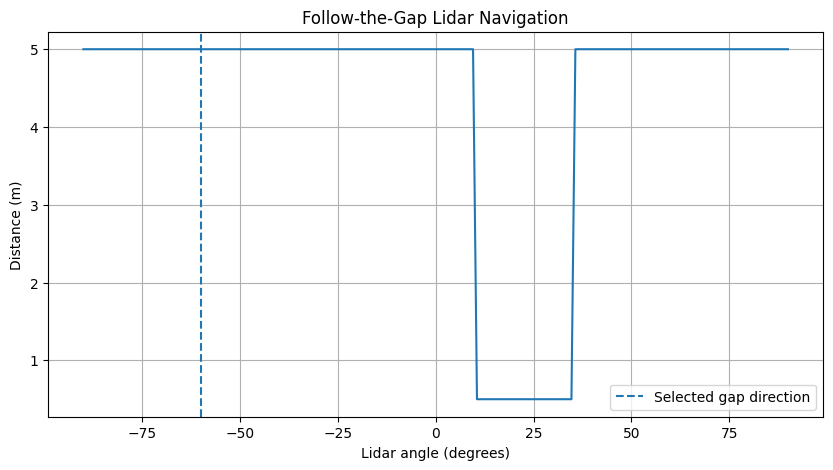

In [11]:
angles = np.linspace(
    -90,
    90,
    len(lidar)
)

plt.figure(figsize=(10, 5))

plt.plot(
    angles,
    lidar
)

plt.axvline(
    np.degrees(target),
    linestyle="--",
    label="Selected gap direction"
)

plt.xlabel("Lidar angle (degrees)")
plt.ylabel("Distance (m)")

plt.title(
    "Follow-the-Gap Lidar Navigation"
)

plt.legend()
plt.grid()

plt.show()